In [164]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [165]:
from sklearn.datasets import load_breast_cancer
X,y = load_breast_cancer(return_X_y=True, as_frame=True)

Prepare the Data

In [166]:
# X = wbc.iloc[:,2:].values
# y = wbc.iloc[:,1].values

X_train, X_hold, y_train, y_hold = train_test_split(X, y, test_size=0.4, random_state=1, stratify=y)
X_valid, X_test, y_valid, y_test = train_test_split(X_hold, y_hold, test_size=0.5, random_state=1, stratify=y_hold)

print(y_train.shape)
print(y_valid.shape)
print(y_test.shape)

(341,)
(114,)
(114,)


create logistic regression model

In [167]:
logreg_mod = model_2 = LogisticRegression(solver='lbfgs', penalty=None, max_iter=5000)
logreg_mod.fit(X_train, y_train)

print('Training Accuracy:  ', round(logreg_mod.score(X_train, y_train),4))
print('Validation Accuracy:', round(logreg_mod.score(X_test, y_test),4))

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Training Accuracy:   0.9912
Validation Accuracy: 0.9912


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [172]:
y_true = y_test

y_pred_log = logreg_mod.predict(X_test)

# count = 0
# for i in range(114):
#     if y_true[i] == 1 and y_pred_log[i]==1: count += 1
# print('tp:',count)

# count = 0
# for i in range(114):
#     if y_true[i] == 0 and y_pred_log[i]==1: count += 1
# print('fp:',count)

# count = 0
# for i in range(114):
#     if y_true[i] == 0 and y_pred_log[i]==0: count += 1
# print('tn:',count)

# count = 0
# for i in range(114):
#     if y_true[i] == 1 and y_pred_log[i]==0: count += 1
# print('fn:',count)

accuracy = np.mean(y_pred_log == y_true)
print('Test Accuracy:', accuracy)

cm = confusion_matrix(y_true, y_pred_log)
print(cm)

pd.DataFrame(cm, index=['Actual No', 'Actual Yes'], columns=['Pred No', 'Pred Yes'], )

Test Accuracy: 0.9912280701754386
[[42  0]
 [ 1 71]]


,Pred No,Pred Yes
Actual No,42,0
Actual Yes,1,71


In [174]:
precision = np.sum((y_pred_log == 1) & (y_true == 1) ) / np.sum(y_pred_log == 1)
recall = np.sum((y_pred_log == 1) & (y_true == 1) ) / np.sum(y_true == 1)

print('True Precision:', round(precision,4))
print('True Recall:   ', round(recall,4))

True Precision: 1.0
True Recall:    0.9861


Create Decision Tree Model¶

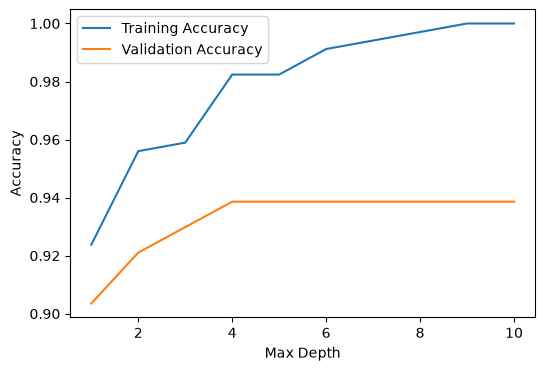

In [175]:
tr_acc = []
va_acc = []

depth_list = range(1,11)

for d in depth_list:
    temp_mod = DecisionTreeClassifier(max_depth=d, random_state=1)
    temp_mod.fit(X_train, y_train)
    tr_acc.append(temp_mod.score(X_train, y_train))
    va_acc.append(temp_mod.score(X_valid, y_valid))
    
plt.figure(figsize=([6,4]))
plt.plot(depth_list, tr_acc, label='Training Accuracy')
plt.plot(depth_list, va_acc, label='Validation Accuracy')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [176]:
ix_best = np.argmax(va_acc)
best_md = depth_list[ix_best]
print('Optimal Value of max_depth:', best_md)

Optimal Value of max_depth: 4


In [177]:
tree_mod = DecisionTreeClassifier(max_depth=best_md, random_state=1)
tree_mod.fit(X_train, y_train)

print('Training Accuracy:  ', round(tree_mod.score(X_train, y_train),4))
print('Validation Accuracy:', round(tree_mod.score(X_valid, y_valid),4))

Training Accuracy:   0.9824
Validation Accuracy: 0.9386


In [178]:
y_pred_tree = tree_mod.predict(X_test)

accuracy = np.mean(y_pred_tree == y_true)
print('Test Accuracy:', accuracy)

cm = confusion_matrix(y_true, y_pred_tree)
print(cm)

pd.DataFrame(cm, index=['Actual No', 'Actual Yes'], columns=['Pred No', 'Pred Yes'])

Test Accuracy: 0.9649122807017544
[[38  4]
 [ 0 72]]


,Pred No,Pred Yes
Actual No,38,4
Actual Yes,0,72


In [180]:
precision = np.sum((y_pred_tree == 1) & (y_true == 1) ) / np.sum(y_pred_tree == 1)
recall = np.sum((y_pred_tree == 1) & (y_true == 1) ) / np.sum(y_true == 1)

print('Precision:', round(precision,4))
print('Recall:   ', round(recall,4))


Precision: 0.9474
Recall:    1.0


create random forest model

In [181]:
forest_mod = RandomForestClassifier(n_estimators=500, max_depth=2, random_state=1)
forest_mod.fit(X_train, y_train)

print('Training Accuracy:  ', round(forest_mod.score(X_train, y_train),4))
print('Validation Accuracy:', round(forest_mod.score(X_valid, y_valid),4))

Training Accuracy:   0.9677
Validation Accuracy: 0.9298


In [182]:
y_pred_forest = forest_mod.predict(X_test)

accuracy = np.mean(y_pred_forest == y_true)
print('Test Accuracy:', accuracy)

cm = confusion_matrix(y_true, y_pred_forest)
print(cm)

pd.DataFrame(cm, index=['Actual No', 'Actual Yes'], columns=['Pred No', 'Pred Yes'])


Test Accuracy: 0.9824561403508771
[[40  2]
 [ 0 72]]


,Pred No,Pred Yes
Actual No,40,2
Actual Yes,0,72


In [183]:
precision = np.sum((y_pred_forest == 1) & (y_true == 1) ) / np.sum(y_pred_forest == 1)
recall = np.sum((y_pred_forest == 1) & (y_true == 1) ) / np.sum(y_true == 1)

print('Precision:', round(precision,4))
print('Recall:   ', round(recall,4))

Precision: 0.973
Recall:    1.0


scoring final model

In [184]:
print('Test Set Accuracy:', round(logreg_mod.score(X_test, y_test),4))

Test Set Accuracy: 0.9912


Task 3:
    Both the tree and forest models would be least likely to give a patient a false negative because their recalls are 1.0. This means that their estimated probability of catching all malignant tumors is 100%.

    However, of the two, forest has a higher precision so that is the best model.
    

Task 4:
    a. Wth the forest model, if the test predicts malignant, the patient has a 97.3% chance of actually having cancer. This is based on the presicision, the estimated probability of a positive prediction being correct, which is 0.973.

    b. If the prediction is benign it has a 100% chance of being benign. This is because there is a 100% chance that all malignant tumors are caught. This in turn means that there a 0% chance that a benign reading would be malignant.

Task 5:
    The advantages of choosing a model that minimizes false negatives over one with better accuracy is that the model misses less positives. This means that doctors have a better chance of being alreted to the disease. 
    The disadvantage is that there could be more false positives due to the lack of accuracy. So, if the treatment for the disease could be harmful if not needed this could be a problem because your chances of giving it to a healthy patient increases. It also increases the stress on more patients who in reality are healthy because they get a false positive.